In [18]:
from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
import numpy as np


In [3]:


tc = pd.read_csv('/content/drive/MyDrive/data sciencist/WA_Fn-UseC_-Telco-Customer-Churn.csv')
tc.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
tc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
tc.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [9]:
count = len(tc[tc['Churn'] == 'No'])
print(f"Devam eden sayısı: {count}")

Devam eden sayısı: 5174


In [8]:
count = len(tc[tc['Churn'] == 'Yes'])
print(f"Kayıp müşteri sayısı: {count}")

Kayıp müşteri sayısı: 1869


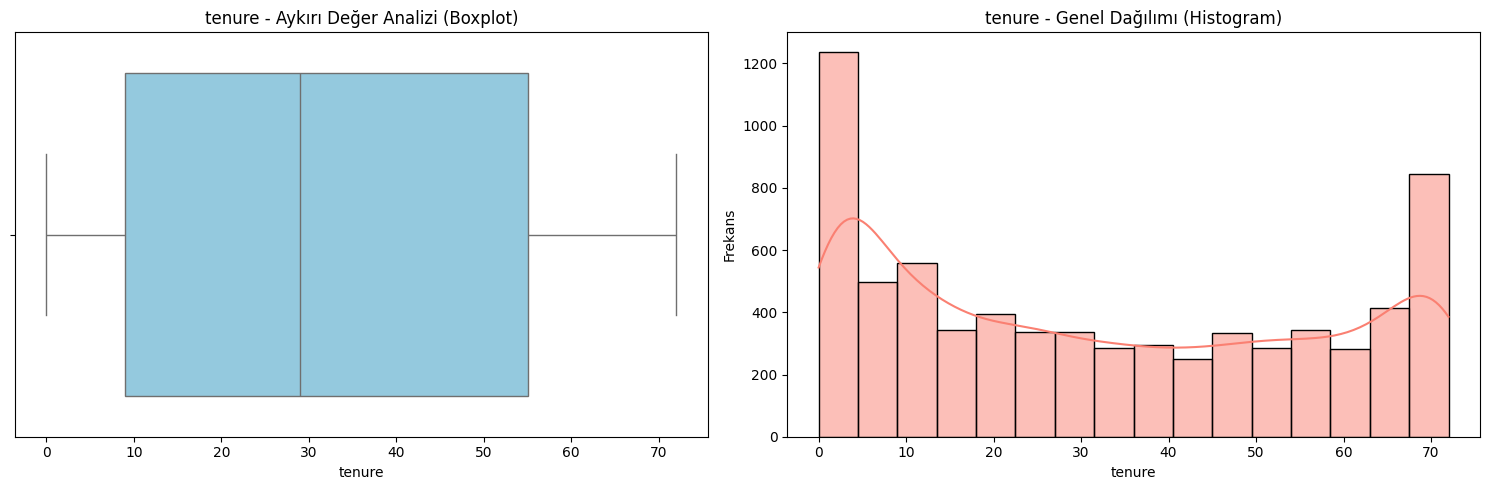

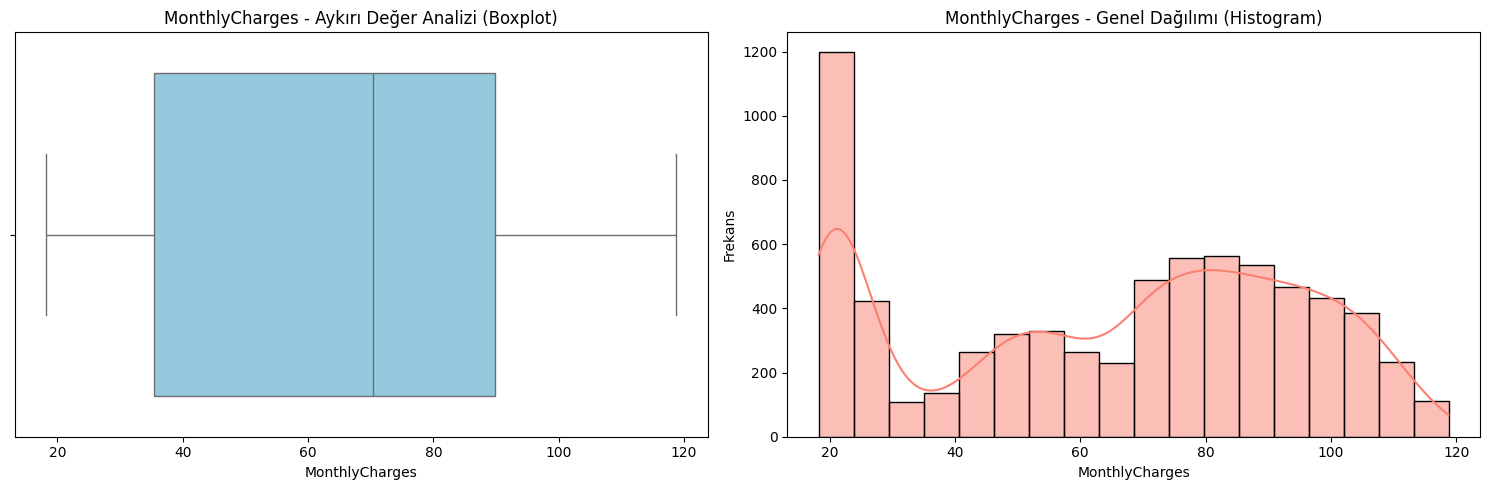

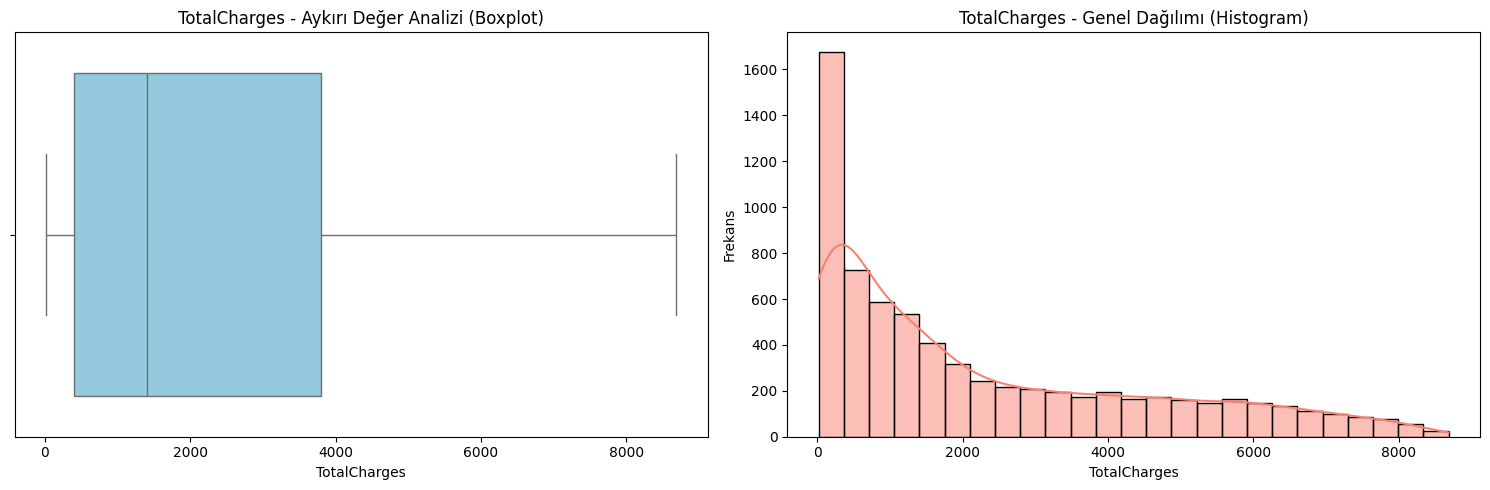

In [11]:


tc['TotalCharges'] = pd.to_numeric(tc['TotalCharges'], errors='coerce')

numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))


    sns.boxplot(ax=axes[0], x=tc[col], color='skyblue')
    axes[0].set_title(f'{col} - Aykırı Değer Analizi (Boxplot)')
    axes[0].set_xlabel(col)


    sns.histplot(ax=axes[1], x=tc[col].dropna(), kde=True, color='salmon')
    axes[1].set_title(f'{col} - Genel Dağılımı (Histogram)')
    axes[1].set_xlabel(col)
    axes[1].set_ylabel('Frekans')

    plt.tight_layout()
    plt.show()

In [14]:
df_model = tc.drop(columns=['customerID']).copy()

df_model['TotalCharges'] = df_model['TotalCharges'].fillna(df_model['TotalCharges'].median())

df_model['Churn'] = df_model['Churn'].map({'Yes': 1, 'No': 0})

df_encoded = pd.get_dummies(df_model, drop_first=True)

X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

auc_score = roc_auc_score(y_test, y_prob)
print("=== LOGISTIC REGRESSION MODEL SONUÇLARI ===\n")
print(f"ROC AUC Skoru: {auc_score:.4f}\n")
print("Sınıflandırma Raporu (Classification Report):")
print(classification_report(y_test, y_pred))

=== LOGISTIC REGRESSION MODEL SONUÇLARI ===

ROC AUC Skoru: 0.8425

Sınıflandırma Raporu (Classification Report):
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.65      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.74      1409
weighted avg       0.80      0.80      0.80      1409



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [15]:

scale_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

model_scaled = LogisticRegression(max_iter=1000, random_state=42)
model_scaled.fit(X_train_scaled, y_train)

y_pred_scaled = model_scaled.predict(X_test_scaled)
y_prob_scaled = model_scaled.predict_proba(X_test_scaled)[:, 1]

auc_score_scaled = roc_auc_score(y_test, y_prob_scaled)
print("=== ÖLÇEKLENDİRİLMİŞ LOGISTIC REGRESSION MODEL SONUÇLARI ===\n")
print(f"Yeni ROC AUC Skoru: {auc_score_scaled:.4f}\n")
print("Sınıflandırma Raporu (Classification Report):")
print(classification_report(y_test, y_pred_scaled))

=== ÖLÇEKLENDİRİLMİŞ LOGISTIC REGRESSION MODEL SONUÇLARI ===

Yeni ROC AUC Skoru: 0.8421

Sınıflandırma Raporu (Classification Report):
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



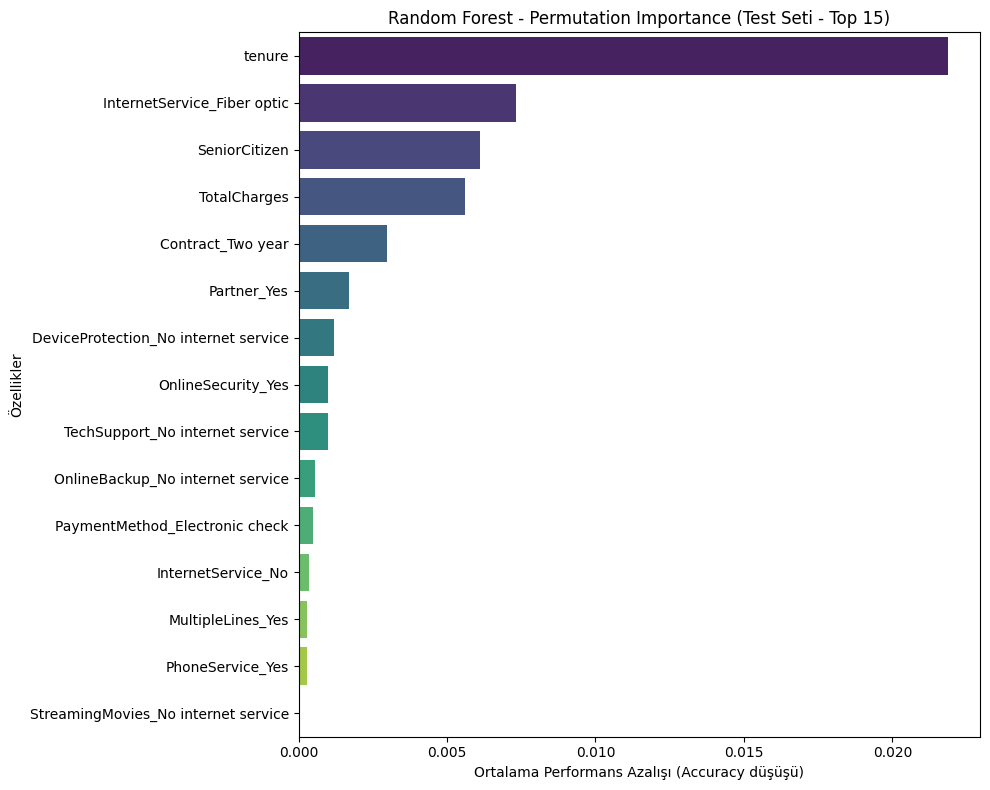

,Feature,Importance_Mean,Importance_Std
1,tenure,2.185947e-02,0.004268
10,InternetService_Fiber optic,7.310149e-03,0.003238
0,SeniorCitizen,6.103620e-03,0.003193
3,TotalCharges,5.606813e-03,0.005142
25,Contract_Two year,2.980837e-03,0.003155
5,Partner_Yes,1.703336e-03,0.003145
16,DeviceProtection_No internet service,1.206529e-03,0.001385
13,OnlineSecurity_Yes,9.936125e-04,0.002964
18,TechSupport_No internet service,9.936125e-04,0.001109
14,OnlineBackup_No internet service,5.677786e-04,0.001899


In [17]:
rf_model = RandomForestClassifier(random_state=42, n_estimators=100)
rf_model.fit(X_train_scaled, y_train)

result = permutation_importance(
    rf_model, X_test_scaled, y_test, n_repeats=10, random_state=42, n_jobs=-1
)

importances_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance_Mean': result.importances_mean,
    'Importance_Std': result.importances_std
}).sort_values(by='Importance_Mean', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(
    x='Importance_Mean',
    y='Feature',
    data=importances_df.head(15),
    palette='viridis',
    hue='Feature',
    legend=False
)
plt.title('Random Forest - Permutation Importance (Test Seti - Top 15)')
plt.xlabel('Ortalama Performans Azalışı (Accuracy düşüşü)')
plt.ylabel('Özellikler')
plt.tight_layout()
plt.show()

display(importances_df.head(15))

In [19]:
# 1. Mevcut Random Forest Modelinin ROC AUC Skoruna Bakalım
rf_prob = rf_model.predict_proba(X_test_scaled)[:, 1]
rf_auc = roc_auc_score(y_test, rf_prob)
print("=== RANDOM FOREST PERFORMANSI ===")
print(f"Random Forest ROC AUC Skoru: {rf_auc:.4f}\n")

=== RANDOM FOREST PERFORMANSI ===
Random Forest ROC AUC Skoru: 0.8246



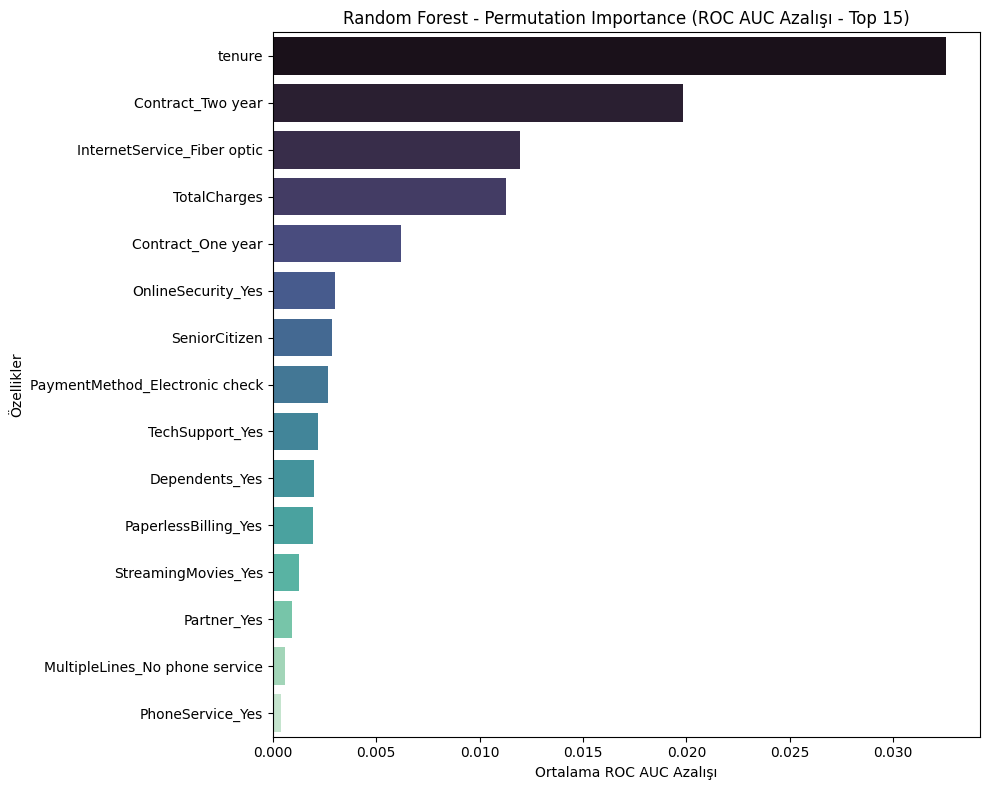

,Feature,Importance_Mean_AUC,Importance_Std_AUC
1,tenure,0.032569,0.004065
25,Contract_Two year,0.019838,0.002119
10,InternetService_Fiber optic,0.011931,0.004297
3,TotalCharges,0.011257,0.002126
24,Contract_One year,0.006200,0.002571
13,OnlineSecurity_Yes,0.003005,0.001883
0,SeniorCitizen,0.002883,0.002307
28,PaymentMethod_Electronic check,0.002672,0.002783
19,TechSupport_Yes,0.002201,0.001622
6,Dependents_Yes,0.002006,0.002733


In [20]:
# 2. Permutation Importance'ı scoring='roc_auc' ile Yeniden Hesaplayalım
result_auc = permutation_importance(
    rf_model, X_test_scaled, y_test, scoring='roc_auc', n_repeats=10, random_state=42, n_jobs=-1
)

importances_auc_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance_Mean_AUC': result_auc.importances_mean,
    'Importance_Std_AUC': result_auc.importances_std
}).sort_values(by='Importance_Mean_AUC', ascending=False)

# İlk 15'i görselleştirelim
plt.figure(figsize=(10, 8))
sns.barplot(
    x='Importance_Mean_AUC',
    y='Feature',
    data=importances_auc_df.head(15),
    palette='mako',
    hue='Feature',
    legend=False
)
plt.title('Random Forest - Permutation Importance (ROC AUC Azalışı - Top 15)')
plt.xlabel('Ortalama ROC AUC Azalışı')
plt.ylabel('Özellikler')
plt.tight_layout()
plt.show()

display(importances_auc_df.head(15))

In [21]:
# 3. class_weight='balanced' ile Lojistik Regresyonu Yeniden Eğitelim (Recall Değişimi)
model_balanced = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model_balanced.fit(X_train_scaled, y_train)

y_pred_balanced = model_balanced.predict(X_test_scaled)
y_prob_balanced = model_balanced.predict_proba(X_test_scaled)[:, 1]

auc_balanced = roc_auc_score(y_test, y_prob_balanced)
print("=== SINIF AĞIRLIKLI (BALANCED) LOGISTIC REGRESSION ===\n")
print(f"Yeni ROC AUC Skoru: {auc_balanced:.4f}\n")
print("Sınıflandırma Raporu:")
print(classification_report(y_test, y_pred_balanced))

=== SINIF AĞIRLIKLI (BALANCED) LOGISTIC REGRESSION ===

Yeni ROC AUC Skoru: 0.8417

Sınıflandırma Raporu:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [22]:
# 4. İş Yorumu için Lojistik Regresyon Katsayılarını Yazdıralım
# Ölçeklendirilmiş lojistik regresyon katsayılarını inceliyoruz
coef_series = pd.Series(model_scaled.coef_[0], index=X.columns).sort_values()

print("=== LOJİSTİK REGRESYON KATSAYILARI (COEFFICIENTS) ===\n")
print("En Çok Churn Azaltan Faktörler (Negatif Etki):")
print(coef_series.head(10))
print("\nEn Çok Churn Artıran Faktörler (Pozitif Etki):")
print(coef_series.tail(10))

=== LOJİSTİK REGRESYON KATSAYILARI (COEFFICIENTS) ===

En Çok Churn Azaltan Faktörler (Negatif Etki):
Contract_Two year                  -1.337453
tenure                             -1.237578
Contract_One year                  -0.690863
PhoneService_Yes                   -0.491306
MonthlyCharges                     -0.477810
OnlineSecurity_Yes                 -0.347516
TechSupport_Yes                    -0.298012
MultipleLines_No phone service     -0.246604
Dependents_Yes                     -0.225854
OnlineBackup_No internet service   -0.174340
dtype: float64

En Çok Churn Artıran Faktörler (Pozitif Etki):
DeviceProtection_Yes              0.037562
PaymentMethod_Mailed check        0.067582
SeniorCitizen                     0.144638
MultipleLines_Yes                 0.365301
PaperlessBilling_Yes              0.371600
PaymentMethod_Electronic check    0.377641
StreamingTV_Yes                   0.378872
StreamingMovies_Yes               0.380384
TotalCharges                      0.51137